# DL · 02 MLP Training and Architecture Selection
Run after `01_data_preparation.ipynb`.

1. **Reference:** reproduce the original setup — a 128/64 network with dropout 0.1, fixed learning rate and 60 epochs, trained on only 300,000 rows.
2. **Search:** train four candidate networks on **all 2,478,761 training rows** and pick the one with the lowest RMSE on the full 2019 validation year.

The test years (2021–2023) are not used here at all.

**Project team**

| Team member | Enrollment number |
|---|---|
| Dhruv Kumar | 2401010152 |
| Ritesh | 2041010383 |
| Yash Kumar | 2401010512 |
| Parul | 2401010321 |
| Punit | 2401010359 |

## 1. Imports and the network definition

In [1]:
from pathlib import Path
import json, hashlib, zipfile
import numpy as np
import pandas as pd
from IPython.display import display, Image
import copy, random, platform, time
from datetime import UTC, datetime
from importlib.metadata import version
import joblib
import torch
from torch import nn
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
# Locate the repository root from either the repo root or the notebook folder.
_here = Path.cwd().resolve()
ROOT = next((p for p in [_here, *_here.parents] if (p / "Datasets" / "Water_Quality_Dataset.zip").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the Water_Quality_Prediction repository.")
PART = ROOT / "DL"              # This part of the project
DATA = ROOT / "Datasets"            # Shared source data
CACHE = DATA / "_working"           # Shared extracted CSV; ignored by Git
WORK = PART / "_working"            # Intermediate files for this part; ignored by Git
FIGURES = PART / "figures"
MODELS = PART / "Models"
RESULTS = PART / "Results"
for folder in [CACHE, WORK, FIGURES, MODELS, RESULTS]:
    folder.mkdir(exist_ok=True)
CSV = CACHE / "Combined_dataset.csv"
EXPECTED_SHA256 = "81ced159f465aa5ab004b77130e5f7147c698876ddbf2f97807e31c9d0e8d714"
FEATURES = [
    "Ammonia (mg/l)",
    "Biochemical Oxygen Demand (mg/l)",
    "Dissolved Oxygen (mg/l)",
    "Orthophosphate (mg/l)",
    "pH (ph units)",
    "Temperature (cel)",
    "Nitrogen (mg/l)",
    "Nitrate (mg/l)",
]
SHORT_NAMES = ["Ammonia", "BOD", "Dissolved oxygen", "Orthophosphate", "pH", "Temperature", "Nitrogen", "Nitrate"]
TARGET = "CCME_Values"
OBJECTIVES = np.array([0.5, 6, 14, 0.05, 8.5, 25, 20, 45])
META = ["Country", "Area", "Waterbody Type", "Date"]
BANDS = ["Poor", "Marginal", "Fair", "Good", "Excellent"]


def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def ensure_csv():
    """Extract the unmodified Figshare CSV from the shared ZIP once, then verify it."""
    if not CSV.exists():
        archive = DATA / "Water_Quality_Dataset.zip"
        if archive.exists():
            import shutil
            with zipfile.ZipFile(archive) as z, z.open("Combined_dataset.csv") as src, CSV.open("wb") as dst:
                shutil.copyfileobj(src, dst)
        else:
            import urllib.request
            urllib.request.urlretrieve("https://ndownloader.figshare.com/files/50757321", CSV)
    assert sha256(CSV) == EXPECTED_SHA256, "Dataset checksum differs from the documented release."
    return CSV


def source_formula(frame):
    """Reconstruct released labels, including denominator 12 and upper-only tests.

    Diagnostic only: this intentionally preserves source methodological issues.
    It is NOT an implementation of the official site/time-window CCME standard.
    """
    x = frame[FEATURES].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=float)
    failed = (x > OBJECTIVES).sum(axis=1)
    excursion = np.maximum(x / OBJECTIVES - 1, 0).sum(axis=1)
    f1 = 100 * failed / 12
    nse = excursion / 12
    f3 = nse / (0.01 * nse + 0.01)
    result = 100 - np.sqrt(2 * f1**2 + f3**2) / 1.732
    result[~np.isfinite(x).all(axis=1)] = np.nan
    return result


def quality_features(frame):
    """Mask invalid readings without deleting pollution extremes or guessing units.

    pH outside [0,14] and negative concentrations become missing. Temperature
    outside [-5,50] C is flagged for review, not converted. Every input gets a
    fixed missing/invalid flag, so the model always receives 16 columns.
    """
    absent = set(FEATURES) - set(frame.columns)
    if absent:
        raise ValueError(f"Missing required measurement columns: {sorted(absent)}")
    x = frame[FEATURES].apply(pd.to_numeric, errors="coerce").astype(float)
    x = x.replace([np.inf, -np.inf], np.nan)
    for col in FEATURES:
        if col == "pH (ph units)":
            invalid = ~x[col].between(0, 14)
        elif col == "Temperature (cel)":
            invalid = ~x[col].between(-5, 50)
        else:
            invalid = x[col] < 0
        x.loc[invalid, col] = np.nan
    flags = x.isna().astype(float)
    flags.columns = [f"{col}__missing" for col in FEATURES]
    return pd.concat([x, flags], axis=1)


def dump_json(path, payload):
    Path(path).write_text(json.dumps(payload, indent=2, allow_nan=False) + "\n")

def seed_everything(seed, threads=4):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(threads)
    torch.use_deterministic_algorithms(True)

class MLP(nn.Module):
    """Feedforward network: [Linear -> ReLU (-> Dropout)] x hidden layers -> Linear(1)."""
    def __init__(self, input_dim=16, widths=(128, 64), dropout=0.0):
        super().__init__()
        layers, size = [], input_dim
        for width in widths:
            layers += [nn.Linear(size, width), nn.ReLU()]
            if dropout:
                layers.append(nn.Dropout(dropout))
            size = width
        layers.append(nn.Linear(size, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x).squeeze(-1)

def predict_mlp(model, x, batch_size=65536):
    """Predict in index points (0-100); the network itself works on target/100."""
    model.eval()
    out = []
    with torch.inference_mode():
        for start in range(0, len(x), batch_size):
            batch = torch.as_tensor(np.asarray(x[start:start + batch_size]), dtype=torch.float32)
            out.append(model(batch).numpy() * 100)
    return np.clip(np.concatenate(out), 0, 100)

def fit_mlp(x, y, xv, yv, spec, config, verbose_every=10):
    """Train one network with AdamW + MSE on target/100.

    spec["schedule"] = "constant" keeps the learning rate fixed (the original setup);
    "onecycle" warms up to spec["lr"] and anneals it to ~0, which lets the network
    settle into a sharper minimum. With validation data the best-RMSE epoch is kept;
    without it (final refit on all years) the last epoch is kept.
    """
    seed_everything(config["seed"], config["threads"])
    model = MLP(x.shape[1], spec["widths"], spec["dropout"])
    optimizer = torch.optim.AdamW(model.parameters(), lr=spec["lr"], weight_decay=config["weight_decay"])
    tx = torch.as_tensor(np.asarray(x), dtype=torch.float32)
    ty = torch.as_tensor(np.asarray(y) / 100, dtype=torch.float32)
    steps_per_epoch = (len(tx) + config["batch_size"] - 1) // config["batch_size"]
    scheduler = None
    if spec["schedule"] == "onecycle":
        scheduler = torch.optim.lr_scheduler.OneCycleLR(
            optimizer, max_lr=spec["lr"], total_steps=spec["epochs"] * steps_per_epoch, pct_start=0.1)
    best_score, best_state, history = float("inf"), None, []
    tick = time.perf_counter()
    for epoch in range(spec["epochs"]):
        model.train()
        total = 0.0
        for ids in torch.randperm(len(tx)).split(config["batch_size"]):
            optimizer.zero_grad(set_to_none=True)
            loss = nn.functional.mse_loss(model(tx[ids]), ty[ids])
            loss.backward()
            optimizer.step()
            if scheduler is not None:
                scheduler.step()
            total += loss.item() * len(ids)
        row = {"epoch": epoch + 1, "train_rmse": float(np.sqrt(total / len(tx)) * 100),
               "lr": optimizer.param_groups[0]["lr"]}
        if xv is not None:
            row["validation_rmse"] = float(np.sqrt(np.mean((predict_mlp(model, xv) - np.asarray(yv)) ** 2)))
            if row["validation_rmse"] < best_score:
                best_score, best_state = row["validation_rmse"], copy.deepcopy(model.state_dict())
        history.append(row)
        if epoch == 0 or (epoch + 1) % verbose_every == 0:
            shown = f"validation RMSE {row['validation_rmse']:.4f}" if xv is not None else f"train RMSE {row['train_rmse']:.4f}"
            print(f"  {spec['name']}: epoch {epoch + 1:>3}, {shown}, {time.perf_counter() - tick:.0f}s", flush=True)
    if best_state is not None:
        model.load_state_dict(best_state)
    model.eval()
    return model, history

In [2]:
bundle = joblib.load(WORK / "prepared.joblib")
xf, yf, xv, yv = bundle["xf"], bundle["yf"], bundle["xv"], bundle["yv"]
sample_ids = bundle["sample_ids"]
TRAIN = {
    "seed": 42, "threads": 4, "batch_size": 2048, "weight_decay": 1e-4,
}
print(f"Training rows: {len(xf):,}  |  validation rows (2019): {len(xv):,}")

Training rows: 2,478,761  |  validation rows (2019): 87,177


## 2. Reference: the original small-sample network
Hidden layers 128/64, ReLU, dropout 0.1, AdamW (lr 0.001), MSE loss on target/100, batch 2,048, 60 epochs. In the original study this model hit its epoch limit while still improving.

In [3]:
reference_spec = {"name": "Original · 300k sample", "widths": [128, 64], "dropout": 0.1,
                  "schedule": "constant", "lr": 1e-3, "epochs": 60}
tick = time.perf_counter()
reference_model, reference_history = fit_mlp(xf[sample_ids], yf[sample_ids], xv, yv, reference_spec, TRAIN)
reference_seconds = time.perf_counter() - tick
print(f"Reference validation RMSE: {min(r['validation_rmse'] for r in reference_history):.4f}")

  Original · 300k sample: epoch   1, validation RMSE 4.8528, 0s


  Original · 300k sample: epoch  10, validation RMSE 2.0002, 2s


  Original · 300k sample: epoch  20, validation RMSE 1.5990, 5s


  Original · 300k sample: epoch  30, validation RMSE 1.3657, 7s


  Original · 300k sample: epoch  40, validation RMSE 1.2625, 9s


  Original · 300k sample: epoch  50, validation RMSE 1.1149, 12s


  Original · 300k sample: epoch  60, validation RMSE 0.9528, 14s


Reference validation RMSE: 0.9340


## 3. Candidate networks on the whole training set
All candidates use the full training history, AdamW with weight decay 1e-4, batch 2,048, 60 epochs and a **one-cycle learning-rate schedule** (warm up to 0.003, then anneal towards zero). We vary depth, width and dropout:

| Candidate | Hidden layers | Dropout | Parameters |
|---|---|---|---|
| A | 128 → 64 | 0.1 | ~10.5k |
| B | 128 → 64 | 0 | ~10.5k |
| C | 256 → 128 | 0 | ~37.4k |
| D | 256 → 128 → 64 | 0 | ~45.6k |

Each epoch is scored on all 87,177 validation rows and the best epoch is kept. *Running all four takes several minutes on a laptop CPU.*

In [4]:
CANDIDATES = [
    {"name": "A · 128-64 · dropout 0.1", "widths": [128, 64], "dropout": 0.1},
    {"name": "B · 128-64 · no dropout", "widths": [128, 64], "dropout": 0.0},
    {"name": "C · 256-128 · no dropout", "widths": [256, 128], "dropout": 0.0},
    {"name": "D · 256-128-64 · no dropout", "widths": [256, 128, 64], "dropout": 0.0},
]
results, histories, trained = [], {reference_spec["name"]: reference_history}, {}
results.append({"candidate": reference_spec["name"], "training_rows": len(sample_ids),
                "parameters": sum(p.numel() for p in reference_model.parameters()),
                "validation_rmse": min(r["validation_rmse"] for r in reference_history),
                "best_epoch": min(reference_history, key=lambda r: r["validation_rmse"])["epoch"],
                "seconds": reference_seconds})
for spec in CANDIDATES:
    spec = {**spec, "schedule": "onecycle", "lr": 3e-3, "epochs": 60}
    print(f"Training {spec['name']} on {len(xf):,} rows...", flush=True)
    tick = time.perf_counter()
    model, history = fit_mlp(xf, yf, xv, yv, spec, TRAIN)
    best = min(history, key=lambda r: r["validation_rmse"])
    results.append({"candidate": spec["name"], "training_rows": len(xf),
                    "parameters": sum(p.numel() for p in model.parameters()),
                    "validation_rmse": best["validation_rmse"], "best_epoch": best["epoch"],
                    "seconds": time.perf_counter() - tick})
    histories[spec["name"]] = history
    trained[spec["name"]] = (spec, model)
search = pd.DataFrame(results)
display(search.round(4))

Training A · 128-64 · dropout 0.1 on 2,478,761 rows...


  A · 128-64 · dropout 0.1: epoch   1, validation RMSE 3.5449, 2s


  A · 128-64 · dropout 0.1: epoch  10, validation RMSE 1.3616, 19s


  A · 128-64 · dropout 0.1: epoch  20, validation RMSE 0.7731, 39s


  A · 128-64 · dropout 0.1: epoch  30, validation RMSE 0.6257, 58s


  A · 128-64 · dropout 0.1: epoch  40, validation RMSE 0.5882, 77s


... (23 outputs left out)

  D · 256-128-64 · no dropout: epoch  40, validation RMSE 0.8371, 58s


  D · 256-128-64 · no dropout: epoch  50, validation RMSE 0.8039, 71s


  D · 256-128-64 · no dropout: epoch  60, validation RMSE 0.7945, 86s


,candidate,training_rows,parameters,validation_rmse,best_epoch,seconds
0,Original · 300k sample,300000,10497,0.9340,59,14.5009
1,A · 128-64 · dropout 0.1,2478761,10497,0.4640,58,115.9844
2,B · 128-64 · no dropout,2478761,10497,0.1553,58,41.7429
3,C · 256-128 · no dropout,2478761,37377,0.2546,60,69.7873
4,D · 256-128-64 · no dropout,2478761,45569,0.6522,16,85.7088


## 4. Select the best network on validation only

In [5]:
full_runs = search[search.training_rows == len(xf)]
best_name = full_runs.loc[full_runs.validation_rmse.idxmin(), "candidate"]
best_spec, best_model = trained[best_name]
print(f"Selected: {best_name}  (validation RMSE {full_runs.validation_rmse.min():.4f})")
search.to_csv(RESULTS / "architecture_search.csv", index=False)
dump_json(RESULTS / "training_history.json", histories)
dump_json(WORK / "selected_spec.json", best_spec)
torch.save(best_model.state_dict(), WORK / "selected_mlp.pt")
torch.save(reference_model.state_dict(), WORK / "reference_mlp.pt")
dump_json(WORK / "reference_spec.json", reference_spec)

Selected: B · 128-64 · no dropout  (validation RMSE 0.1553)


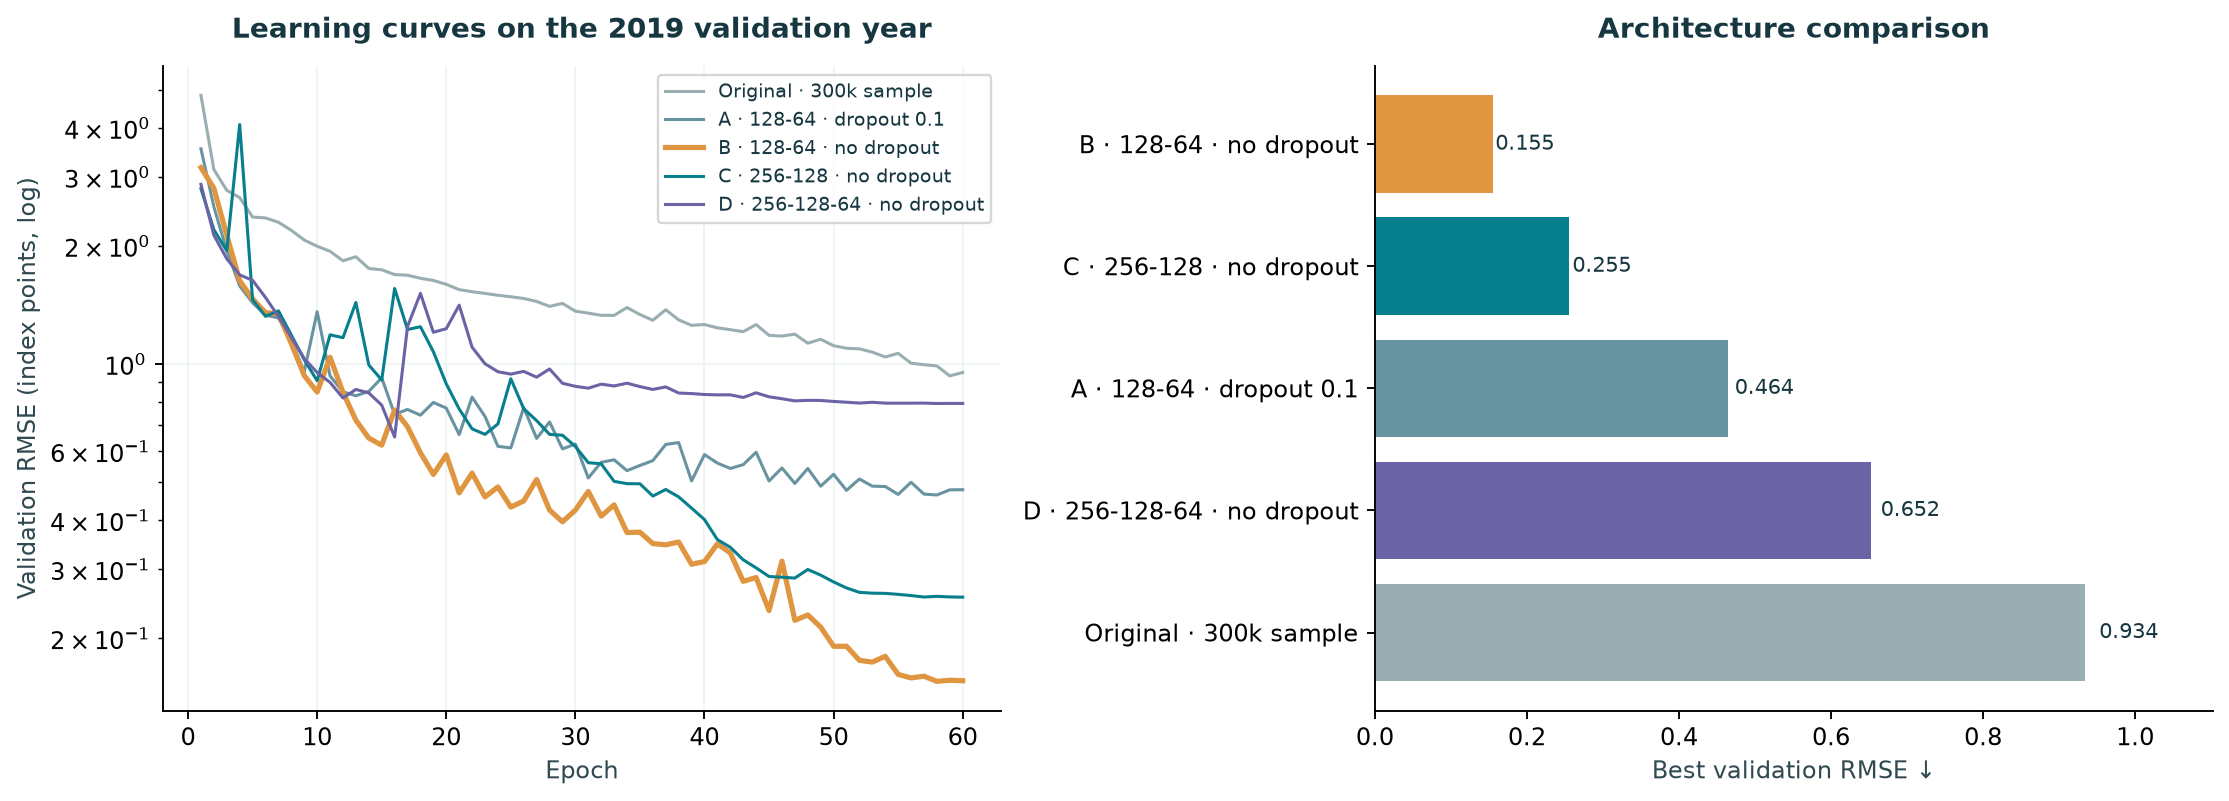

In [6]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelcolor": "#314a52", "text.color": "#163640",
                     "axes.titleweight": "bold", "axes.titlepad": 12,
                     "grid.color": "#dfe9ea", "axes.axisbelow": True})

def show_figure(fig, name):
    path = FIGURES / name
    fig.savefig(path, dpi=170, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(filename=str(path)))

palette = {"Original · 300k sample": "#9aaeb2", "A · 128-64 · dropout 0.1": "#6893a1",
           "B · 128-64 · no dropout": "#e09540", "C · 256-128 · no dropout": "#087f8c",
           "D · 256-128-64 · no dropout": "#6a63a6"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), layout="constrained")
for name, history in histories.items():
    axes[0].plot([r["epoch"] for r in history], [r["validation_rmse"] for r in history],
                 label=name, color=palette[name], linewidth=2.2 if name == best_name else 1.3)
axes[0].set(xlabel="Epoch", ylabel="Validation RMSE (index points, log)", yscale="log",
            title="Learning curves on the 2019 validation year")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.5)
order = search.sort_values("validation_rmse", ascending=False)
axes[1].barh(order.candidate, order.validation_rmse, color=[palette[n] for n in order.candidate])
for i, v in enumerate(order.validation_rmse):
    axes[1].text(v * 1.02, i, f"{v:.3f}", va="center", fontsize=9)
axes[1].set(xlabel="Best validation RMSE ↓", title="Architecture comparison")
axes[1].set_xlim(0, order.validation_rmse.max() * 1.18)
show_figure(fig, "learning_curves.png")

## What we learned
* **More data is the biggest lever.** The same 128/64 design improves sharply when it sees all 2.48 million training rows instead of 300,000.
* **Dropout hurts here.** The target is a deterministic formula with no label noise, so regularizing with dropout only blurs the sharp thresholds the network must learn.
* **A one-cycle schedule** lets training settle instead of stalling at a fixed learning rate.
* **Bigger is not automatically better.** With the same recipe, the wider (256-128) and deeper (256-128-64) networks trained less stably at the 0.003 peak learning rate and finished worse, so the compact 128-64 network wins.

Continue with **03_final_model.ipynb** for the untouched test evaluation, intervals, explanations and the final all-years model.